# Predicting Na/Fe and O/Fe from Photometry — Retried with Dust Removed

**Does correcting the photometry for interstellar dust, and measuring each star against its own cluster's ridgeline, let us predict sodium and oxygen abundances from Hubble colours?**

> The collapsed code cells (setup, data, helpers) do the preparation. Every number and figure below is computed from them, so rerunning the notebook refreshes the whole report.

### The idea in plain words
Stars in a globular cluster are not all identical. Some are "first generation" and some are "second generation", and the two have different amounts of sodium (Na) and oxygen (O). Hubble ultraviolet colours are sensitive to these differences, so in principle **a star's colours should tell us its Na/Fe and O/Fe**.

Earlier attempts struggled. This notebook fixes three things:

1. **Dust.** Dust reddens and dims starlight, and by a different amount in every cluster. We showed earlier that the Hubble data were not corrected for this. So the first step is to remove the dust effect from every star's magnitudes and colours, using each cluster's dust amount and a standard extinction law.
2. **Ridgeline offsets.** A star's *raw* colour mostly reflects its cluster and how bright it is. What matters for chemistry is how far the star sits from **its own cluster's red-giant ridgeline**. A star slightly bluer or redder than the cluster's typical track is what flags a different stellar population (the same idea as the "chromosome map"). We compute those offsets using the dust-corrected ridgelines we built.
3. **A fair test.** Previously, stars from the same cluster appeared in both training and test sets. Because cluster-wide properties (like age) identify the cluster, a model can "cheat" by memorising each cluster's typical value. Here we **hold out entire clusters**, so the test always asks: *can we predict stars in clusters the model has never seen?*

In [1]:
import os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import RidgeCV
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11, 'axes.labelsize': 11})

PROJECT_DIR = Path().resolve()
while PROJECT_DIR.name != 'spectroscopy-regression' and PROJECT_DIR != PROJECT_DIR.parent:
    PROJECT_DIR = PROJECT_DIR.parent
os.chdir(PROJECT_DIR)

TARGETS = ['Na/Fe', 'O/Fe']
BANDS = ['F275W', 'F336W', 'F438W', 'F606W', 'F814W']
SEQ = [('F275W', 'F336W'), ('F336W', 'F438W'), ('F438W', 'F606W'), ('F606W', 'F814W')]
RANGES = {'F275W_abs': (2, 10), 'F336W_abs': (0, 6), 'F438W_abs': (-2, 5), 'F606W_abs': (-5, 4), 'F814W_abs': (-5, 3)}
MINUS = '\u2212'

In [2]:
# 1. Pool the original train and test files (they are random star-level halves of one catalogue) and apply the old quality cuts.
df = pd.concat([pd.read_csv('data/Na_Fe_training_data.csv'), pd.read_csv('data/Na_Fe_TEST_DATA.csv')], ignore_index=True)
n_pooled = len(df)
for c, (lo, hi) in RANGES.items():
    df = df[df[c].isna() | ((df[c] >= lo) & (df[c] <= hi))]
df = df[df[[b + '_abs' for b in BANDS]].notna().all(axis=1)].copy()          # need all five filters

# 2. Cluster-level inputs: dust extinction per filter (from E(B-V) + extinction law), and Harris [Fe/H] as a fallback for stars with no spectroscopic Fe/H.
Atab = pd.read_csv('data/GC_extinction_per_cluster.csv').set_index('NGC')
harris_feh = pd.read_csv('data/GC_metallicity_harris.csv').set_index('NGC')['Fe/H_harris']
df['FeH'] = df['Fe/H'].fillna(df['NGC'].map(harris_feh))
df['age'] = df['age_Kruijssen']
df['EBV'] = df['NGC'].map(Atab['EBV'])

# 3. Remove the dust:  M_0 = M_obs - A_filter ;  colour_0 = colour_obs - (A_X - A_Y)
for b in BANDS:
    df[b + '_0'] = df[b + '_abs'] - df['NGC'].map(Atab['A_' + b])
for x, y in SEQ:
    df[f'c_{x}{y}_raw'] = df[x + '_abs'] - df[y + '_abs']
    df[f'c_{x}{y}'] = df[x + '_0'] - df[y + '_0']

# 4. Offset of each star from its own cluster's (dust-corrected) ridgeline, at the star's own brightness.
for x, y in SEQ:
    df[f'd_{x}{y}'] = np.nan
for n, g in df.groupby('NGC'):
    f = Path(f'data/GC_Ridgelines_dereddened/NGC{n}_F814W_ridge.csv')
    if not f.exists():
        continue
    r = pd.read_csv(f)
    r = r[r['low_conf'].astype(str) == 'False'].dropna().sort_values('F814W_abs')
    if len(r) < 3:
        continue
    m = g['F814W_0'].to_numpy()
    inside = (m >= r['F814W_abs'].min()) & (m <= r['F814W_abs'].max())
    for x, y in SEQ:
        ridge = np.interp(m, r['F814W_abs'], r[f'{x}-{y}'])
        df.loc[g.index, f'd_{x}{y}'] = np.where(inside, g[f'c_{x}{y}'].to_numpy() - ridge, np.nan)

C4 = [f'c_{x}{y}' for x, y in SEQ]; R4 = [f'c_{x}{y}_raw' for x, y in SEQ]; D4 = [f'd_{x}{y}' for x, y in SEQ]
df['has_ridge'] = df[D4].notna().all(axis=1).astype(float)      # clusters/stars without a usable ridgeline get offset 0 + this flag
df[D4] = df[D4].fillna(0.0)

df.drop(columns=[c for c in df.columns if c.endswith('_e') or c in ('Fe/H_e', 'Fe/H_o')], errors='ignore').to_csv('data/Stars_dereddened.csv', index=False)

FEATURE_SETS = {
    'Old setup':                         ['F606W_abs'] + R4 + ['FeH', 'age'],
    'Dust-corrected':                    ['F606W_0'] + C4 + ['FeH', 'age'],
    '+ ridgeline offsets':               ['F606W_0'] + C4 + D4 + ['has_ridge', 'FeH', 'age'],
    '+ offsets, no age (final)':         ['F606W_0'] + C4 + D4 + ['has_ridge', 'FeH'],
}
FINAL = '+ offsets, no age (final)'
clusters = np.array(sorted(df['NGC'].unique()))
print(f'{n_pooled} stars pooled -> {len(df)} with all five filters and passing the cuts; {len(clusters)} clusters; '
      f'{int(df.has_ridge.sum())} stars ({df[df.has_ridge == 1].NGC.nunique()} clusters) have ridgeline offsets')

683 stars pooled -> 494 with all five filters and passing the cuts; 27 clusters; 386 stars (24 clusters) have ridgeline offsets


In [3]:
class Average:
    """Average the predictions of several models."""
    def __init__(self, makers): self.makers = makers
    def fit(self, X, y): self.models = [m().fit(X, y) for m in self.makers]; return self
    def predict(self, X): return np.mean([m.predict(X) for m in self.models], axis=0)

def ET(leaf=5): return ExtraTreesRegressor(200, min_samples_leaf=leaf, n_jobs=-1, random_state=0)
def RF(leaf=5): return RandomForestRegressor(200, min_samples_leaf=leaf, max_features=0.5, n_jobs=-1, random_state=0)
def HGB(): return HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, min_samples_leaf=10, l2_regularization=1.0)
def svr(C): return lambda: make_pipeline(StandardScaler(), SVR(C=C, epsilon=0.05))
MODELS = {'ExtraTrees (leaf 5)': ET, 'ExtraTrees (leaf 15)': lambda: ET(15), 'RandomForest (leaf 5)': RF, 'RandomForest (leaf 15)': lambda: RF(15), 'HistGradBoost': HGB,
          'SVR (C=0.3)': svr(0.3), 'SVR (C=1)': svr(1), 'SVR (C=3)': svr(3),
          'Ridge': lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))),
          'ExtraTrees + SVR': lambda: Average([ET, svr(1)])}
mse = lambda p, y: float(np.mean((np.asarray(p) - np.asarray(y)) ** 2))

def cluster_folds(groups, n_folds=5, seed=0):
    """Random partition of *clusters* (not stars) into folds."""
    ug = np.unique(groups)
    return np.array_split(np.random.default_rng(seed).permutation(ug), n_folds)

def grouped_cv_mse(maker, X, y, groups, reps=2, n_folds=5):
    """Mean squared error when whole clusters are held out."""
    out = []
    for rep in range(reps):
        P = np.zeros(len(y))
        for fold in cluster_folds(groups, n_folds, seed=rep):
            te = np.isin(groups, fold)
            P[te] = maker().fit(X[~te], y[~te]).predict(X[te])
        out.append(mse(P, y))
    return float(np.mean(out))

def grouped_cv_predict(maker, X, y, groups, n_folds=5, seed=0):
    P = np.zeros(len(y))
    for fold in cluster_folds(groups, n_folds, seed=seed):
        te = np.isin(groups, fold)
        P[te] = maker().fit(X[~te], y[~te]).predict(X[te])
    return P

def select_spec(train, target, reps=2):
    """Choose the (feature set, model) pair with the lowest cluster-held-out error on the TRAINING clusters only."""
    d = train.dropna(subset=[target])
    y, g = d[target].to_numpy(), d['NGC'].to_numpy()
    table = pd.DataFrame({mn: {fs: grouped_cv_mse(mk, d[cols].to_numpy(), y, g, reps) for fs, cols in FEATURE_SETS.items()}
                          for mn, mk in MODELS.items()})
    fs, mn = table.stack().idxmin()
    return fs, mn, table

def run_split(test_clusters, target, reps=2):
    """Hold out whole clusters; select (features, model) on the training clusters; refit; evaluate once on the held-out clusters."""
    d = df.dropna(subset=[target])
    is_test = d['NGC'].isin(test_clusters).to_numpy()
    tr, te = d[~is_test], d[is_test]
    fs, mn, table = select_spec(tr, target, reps)
    cols = FEATURE_SETS[fs]
    model = MODELS[mn]().fit(tr[cols].to_numpy(), tr[target].to_numpy())
    ptr, pte = model.predict(tr[cols].to_numpy()), model.predict(te[cols].to_numpy())
    return dict(features=fs, model=mn, table=table, train=tr, test=te, p_train=ptr, p_test=pte,
                mse_train=mse(ptr, tr[target]), mse_test=mse(pte, te[target]),
                mse_baseline=mse(np.full(len(te), tr[target].mean()), te[target]))

## 1. The data

We pooled your training and test files (they were random halves of the same catalogue) and applied the same quality cuts as before. Each star keeps its sodium and oxygen abundance, five Hubble magnitudes, its cluster's age and metallicity, and now its cluster's dust amount.

In [4]:
summary = pd.DataFrame({'stars': [len(df.dropna(subset=['Na/Fe'])), len(df.dropna(subset=['O/Fe']))],
                        'clusters': [df.dropna(subset=['Na/Fe']).NGC.nunique(), df.dropna(subset=['O/Fe']).NGC.nunique()],
                        'variance of target': [df['Na/Fe'].var(), df['O/Fe'].var()],
                        'of which within-cluster': [df.groupby('NGC')['Na/Fe'].transform(lambda s: s - s.mean()).var(),
                                                    df.dropna(subset=['O/Fe']).groupby('NGC')['O/Fe'].transform(lambda s: s - s.mean()).var()]},
                       index=['Na/Fe', 'O/Fe']).round(3)
display(summary)
display(Markdown('The **variance** is the error you would get by always guessing the average, so it is the number to beat. Most of it (right column) is *star-to-star scatter inside each cluster*, not differences between clusters. That is the part that stellar populations, and therefore colours relative to the cluster ridgeline, should explain.'))

,stars,clusters,variance of target,of which within-cluster
Na/Fe,494,27,0.077,0.060
O/Fe,402,27,0.097,0.066


The **variance** is the error you would get by always guessing the average, so it is the number to beat. Most of it (right column) is *star-to-star scatter inside each cluster*, not differences between clusters. That is the part that stellar populations, and therefore colours relative to the cluster ridgeline, should explain.

### What does the dust correction and ridgeline offset do to a star's colour?

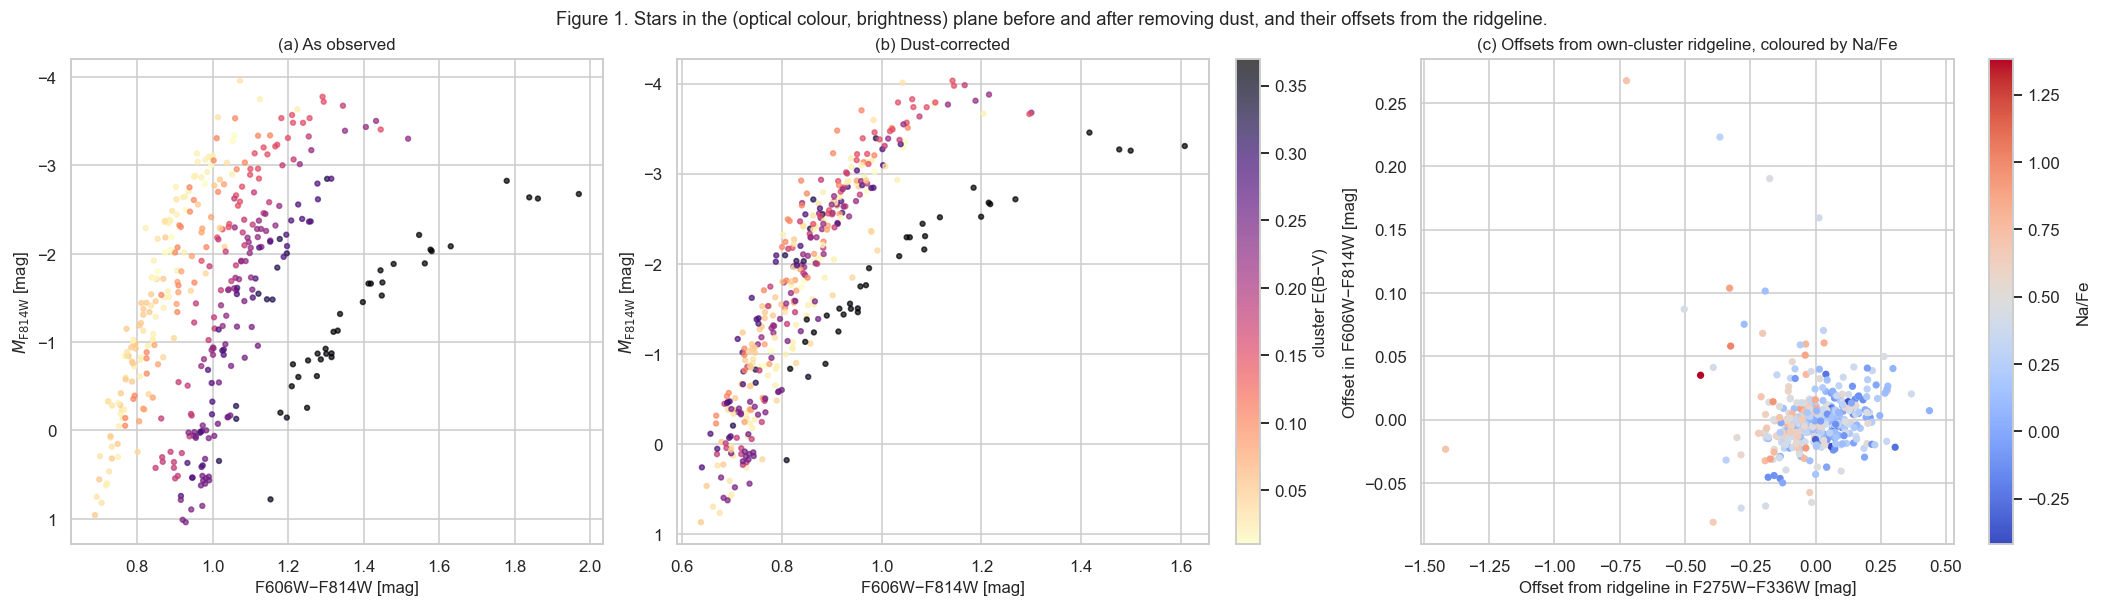

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.4), constrained_layout=True)
pick = df[df.has_ridge == 1]
cmap = plt.cm.magma_r; norm = plt.Normalize(df.EBV.min(), df.EBV.max())
for ax, (xc, yc, title) in zip(axes[:2], [('c_F606W' + 'F814W' + '_raw', 'F814W_abs', '(a) As observed'), ('c_F606W' + 'F814W', 'F814W_0', '(b) Dust-corrected')]):
    sc = ax.scatter(pick[xc], pick[yc], c=pick.EBV, cmap=cmap, norm=norm, s=10, alpha=0.7)
    ax.invert_yaxis(); ax.set_xlabel('F606W' + MINUS + 'F814W [mag]'); ax.set_ylabel(r'$M_{\mathrm{F814W}}$ [mag]'); ax.set_title(title)
fig.colorbar(sc, ax=axes[1], label='cluster E(B' + MINUS + 'V)')
sc = axes[2].scatter(pick['d_F275WF336W'], pick['d_F606WF814W'], c=pick['Na/Fe'], cmap='coolwarm', s=14)
axes[2].set_xlabel('Offset from ridgeline in F275W' + MINUS + 'F336W [mag]'); axes[2].set_ylabel('Offset in F606W' + MINUS + 'F814W [mag]')
axes[2].set_title('(c) Offsets from own-cluster ridgeline, coloured by Na/Fe'); fig.colorbar(sc, ax=axes[2], label='Na/Fe')
fig.suptitle('Figure 1. Stars in the (optical colour, brightness) plane before and after removing dust, and their offsets from the ridgeline.', fontsize=12)
plt.show()

**In plain words (Figure 1).** (a) Raw: stars from different clusters are scattered sideways, because each cluster has a different amount of dust (colour of dots). (b) After removing dust most clusters pile onto one much narrower red-giant track. The cluster that stays redder (the dark dots) is NGC 6388, which is very metal-rich, so a genuine offset is expected. (c) Each star is now measured against *its own* cluster's ridgeline. There is a visible but overlapping trend: sodium-rich stars (red) tend to sit toward smaller F275W\u2212F336W offsets, sodium-poor stars (blue) toward larger ones. The overlap is why this is a partial, not a clean, signal.

## 2. How we split the data (and why)

* **Split by cluster, not by star.** A random split of stars puts siblings from the same cluster in both halves. We instead hold out *whole clusters*: about one quarter of the clusters become the test set and are not touched until the very end.
* **Choose everything on the training clusters only.** The best combination of input set and model for each target is picked with a "leave some clusters out" cross-validation *inside the training clusters*. The held-out test clusters are used once, for the final score.
* **Don't trust a single split.** With only ~27 clusters, one test set of six or seven clusters is noisy, so we also repeat the entire procedure (including model selection) on many different random cluster splits.

In [6]:
SEED = 42                                    # fixed in advance, not tuned
rng = np.random.default_rng(SEED)
test_clusters = np.sort(rng.choice(clusters, size=int(round(0.25 * len(clusters))), replace=False))
train_clusters = np.setdiff1d(clusters, test_clusters)
n_test = df['NGC'].isin(test_clusters).sum()
display(Markdown(f'**Held-out test clusters ({len(test_clusters)}):** NGC ' + ', '.join(map(str, test_clusters)) +
                 f'  ({n_test} stars)  \n**Training clusters ({len(train_clusters)}):** NGC ' + ', '.join(map(str, train_clusters)) + f'  ({len(df) - n_test} stars)'))

**Held-out test clusters (7):** NGC 288, 362, 5904, 6254, 6397, 6809, 6934  (86 stars)  
**Training clusters (20):** NGC 104, 1261, 1851, 2808, 3201, 4590, 4833, 5139, 5986, 6093, 6121, 6205, 6388, 6535, 6584, 6715, 6752, 6838, 7078, 7099  (408 stars)

## 3. Do the new features help? (training clusters only)

We compare four input sets using cluster-held-out cross-validation inside the **training** clusters. Smaller error is better, and the dashed line is the "guess the average" baseline.

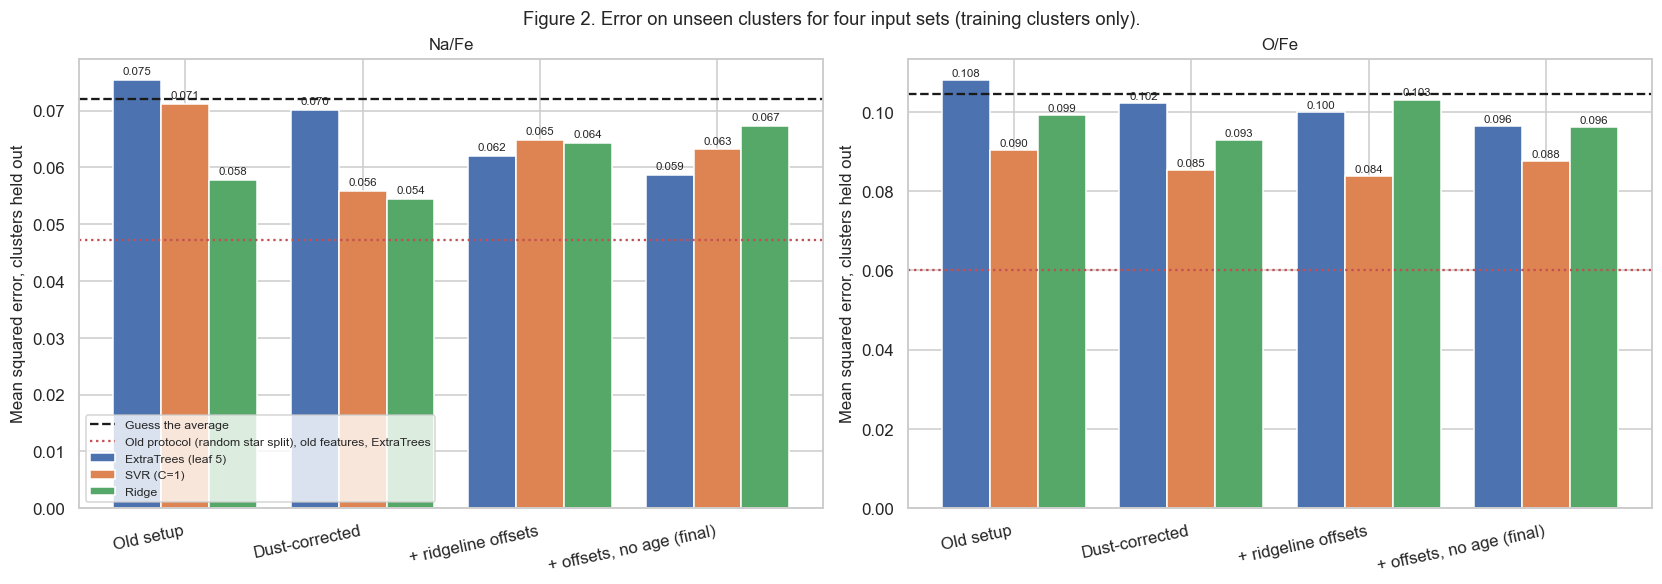

In [7]:
train_df = df[df.NGC.isin(train_clusters)]
ABL_MODELS = ['ExtraTrees (leaf 5)', 'SVR (C=1)', 'Ridge']
abl = {}
for target in TARGETS:
    for fs, cols in FEATURE_SETS.items():
        d = train_df.dropna(subset=cols + [target])
        X, y, g = d[cols].to_numpy(), d[target].to_numpy(), d['NGC'].to_numpy()
        for mn in ABL_MODELS:
            abl[(target, fs, mn)] = grouped_cv_mse(MODELS[mn], X, y, g, reps=3)
# for reference: the old protocol (random star split) on the old features
leaky = {}
for target in TARGETS:
    cols = FEATURE_SETS['Old setup']; d = train_df.dropna(subset=cols + [target]); X, y = d[cols].to_numpy(), d[target].to_numpy()
    P = np.zeros(len(y))
    for tri, tei in KFold(5, shuffle=True, random_state=0).split(X): P[tei] = ET().fit(X[tri], y[tri]).predict(X[tei])
    leaky[target] = mse(P, y)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), constrained_layout=True)
for ax, target in zip(axes, TARGETS):
    x = np.arange(len(FEATURE_SETS)); w = 0.27
    for j, mn in enumerate(ABL_MODELS):
        vals = [abl[(target, fs, mn)] for fs in FEATURE_SETS]
        bars = ax.bar(x + (j - 1) * w, vals, w, label=mn)
        for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v + 0.001, f'{v:.3f}', ha='center', fontsize=7.5)
    ax.axhline(train_df[target].var(), color='k', ls='--', label='Guess the average')
    ax.axhline(leaky[target], color='C3', ls=':', label='Old protocol (random star split), old features, ExtraTrees')
    ax.set_xticks(x); ax.set_xticklabels(list(FEATURE_SETS), rotation=12, ha='right')
    ax.set_ylabel('Mean squared error, clusters held out'); ax.set_title(target)
axes[0].legend(fontsize=8)
fig.suptitle('Figure 2. Error on unseen clusters for four input sets (training clusters only).', fontsize=12)
plt.show()

**In plain words (Figure 2).** Lower is better. The dashed black line is what you get by always guessing the average. The dotted red line shows how good the *old* setup *looked* under the old random split of stars. Compare it with the honest blue 'Old setup' bar (same model, whole clusters held out): the error roughly doubles, and for Na/Fe the old features are barely better than guessing the average. That gap is the cheating by cluster memorisation that we removed.

**What helps (in this run).** Correcting for dust lowers the error for every model and both elements (e.g. Na/Fe with SVR: 0.071 \u2192 0.056; O/Fe with SVR: 0.090 \u2192 0.085). Adding the ridgeline offsets helps the tree models most (Na/Fe ExtraTrees 0.070 \u2192 0.062) but does not beat the best SVR or ridge model for Na/Fe, and gains for O/Fe are small. So the benefit of each ingredient depends on the model, and the gaps between the best bars are small compared with the noise. That is why the next section lets the training clusters choose the combination.

## 4. Final model: train on training clusters, test on held-out clusters

For each target we consider every combination of the four input sets above and ten models (four tree ensembles of different strictness, gradient boosting, three SVR strengths, ridge regression, and a tree + SVR average). The combination with the lowest cluster-held-out cross-validation error on the **training clusters** is picked, refitted on all training stars, and scored once on the held-out clusters. All models minimise squared error (MSE).

In [8]:
cols = FEATURE_SETS[FINAL]
main = {t: run_split(test_clusters, t, reps=3) for t in TARGETS}
tab = pd.DataFrame({t: {'selected input set': r['features'], 'selected model': r['model'], 'train stars': len(r['train']), 'test stars': len(r['test']),
                        'train MSE': r['mse_train'], 'TEST MSE': r['mse_test'],
                        'test MSE if guessing the average': r['mse_baseline'],
                        'test R\u00b2': 1 - r['mse_test'] / r['mse_baseline']} for t, r in main.items()})
display(tab)
for t, r in main.items():
    display(Markdown(f'**{t}: cross-validation MSE on the training clusters** (rows: input set, columns: model)'))
    display(r['table'].round(4))

,Na/Fe,O/Fe
selected input set,Dust-corrected,Dust-corrected
selected model,Ridge,SVR (C=0.3)
train stars,408,342
test stars,86,60
train MSE,0.048097,0.040982
TEST MSE,0.086953,0.026469
test MSE if guessing the average,0.104901,0.056752
test R²,0.171095,0.533607


**Na/Fe: cross-validation MSE on the training clusters** (rows: input set, columns: model)

,ExtraTrees (leaf 5),ExtraTrees (leaf 15),RandomForest (leaf 5),RandomForest (leaf 15),HistGradBoost,SVR (C=0.3),SVR (C=1),SVR (C=3),Ridge,ExtraTrees + SVR
Old setup,0.0754,0.0767,0.0752,0.0754,0.0723,0.0735,0.0712,0.0719,0.0578,0.0684
Dust-corrected,0.0701,0.0733,0.0703,0.0731,0.0716,0.0632,0.0559,0.0583,0.0545,0.0587
+ ridgeline offsets,0.0620,0.0616,0.0600,0.0617,0.0644,0.0635,0.0648,0.0615,0.0644,0.0609
"+ offsets, no age (final)",0.0587,0.0594,0.0584,0.0597,0.0626,0.0638,0.0632,0.0596,0.0673,0.0587


**O/Fe: cross-validation MSE on the training clusters** (rows: input set, columns: model)

,ExtraTrees (leaf 5),ExtraTrees (leaf 15),RandomForest (leaf 5),RandomForest (leaf 15),HistGradBoost,SVR (C=0.3),SVR (C=1),SVR (C=3),Ridge,ExtraTrees + SVR
Old setup,0.1081,0.1104,0.1090,0.1119,0.1105,0.0928,0.0904,0.0971,0.0991,0.0936
Dust-corrected,0.1021,0.1060,0.1001,0.1033,0.0996,0.0817,0.0854,0.0992,0.0929,0.0880
+ ridgeline offsets,0.0999,0.1044,0.0945,0.0958,0.0974,0.0868,0.0838,0.0875,0.1031,0.0877
"+ offsets, no age (final)",0.0964,0.1042,0.0920,0.0940,0.0924,0.0920,0.0876,0.0828,0.0962,0.0882


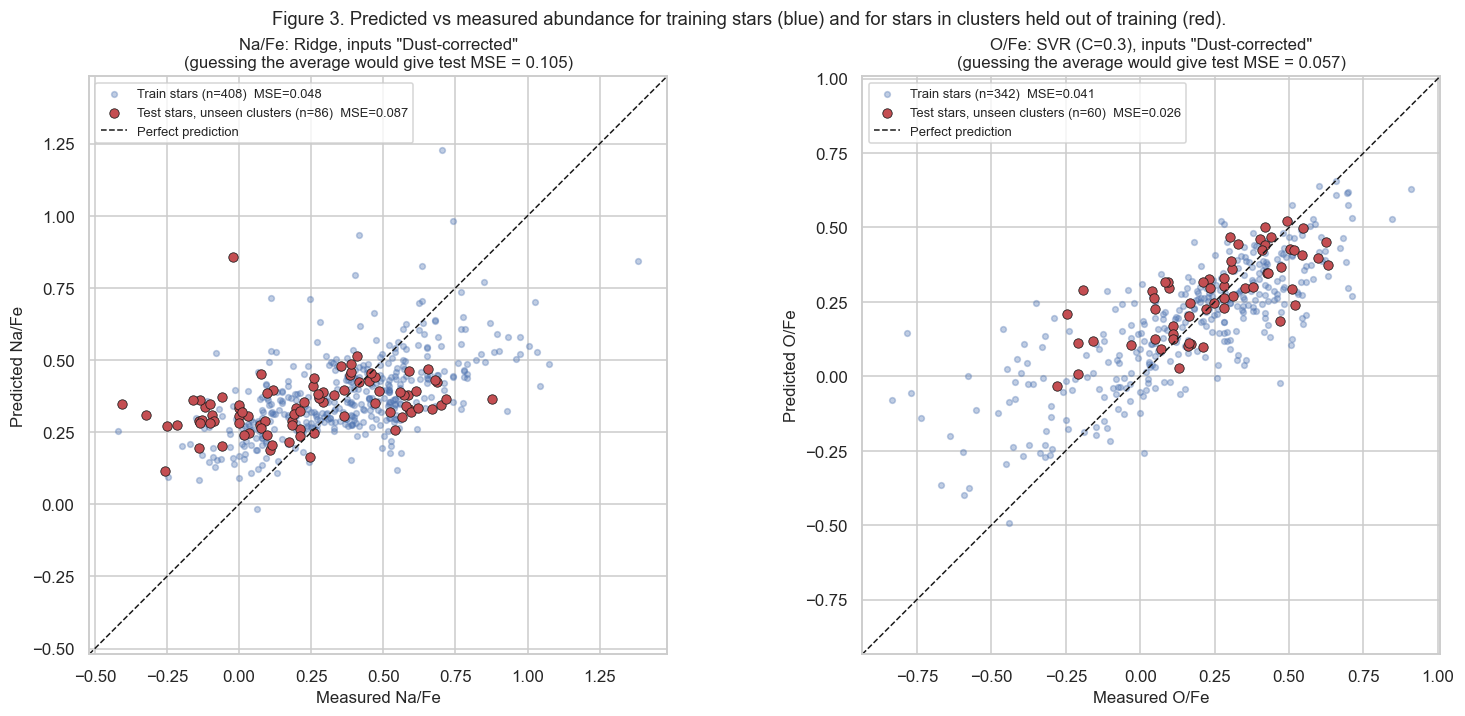

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.4), constrained_layout=True)
for ax, target in zip(axes, TARGETS):
    r = main[target]
    ytr, yte = r['train'][target].to_numpy(), r['test'][target].to_numpy()
    lo, hi = min(ytr.min(), yte.min(), r['p_train'].min(), r['p_test'].min()) - 0.1, max(ytr.max(), yte.max(), r['p_train'].max(), r['p_test'].max()) + 0.1
    ax.scatter(ytr, r['p_train'], s=14, alpha=0.35, color='C0', label=f'Train stars (n={len(ytr)})  MSE={r["mse_train"]:.3f}')
    ax.scatter(yte, r['p_test'], s=38, color='C3', edgecolor='k', linewidth=0.5, label=f'Test stars, unseen clusters (n={len(yte)})  MSE={r["mse_test"]:.3f}')
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='Perfect prediction')
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect('equal')
    ax.set_xlabel(f'Measured {target}'); ax.set_ylabel(f'Predicted {target}')
    ax.set_title(f'{target}: {r["model"]}, inputs "{r["features"]}"\n(guessing the average would give test MSE = {r["mse_baseline"]:.3f})')
    ax.legend(loc='upper left', fontsize=8.5)
fig.suptitle('Figure 3. Predicted vs measured abundance for training stars (blue) and for stars in clusters held out of training (red).', fontsize=12)
plt.show()

**In plain words (Figure 3).** Each dot is a star. The x-axis is the abundance measured from its spectrum; the y-axis is what the model predicts from the star's colours and brightness alone. Dots on the dashed line would be perfect. Blue dots are stars the model was trained on; red dots are stars from **clusters it has never seen**.

* **Na/Fe:** the predictions are squeezed into a narrow band (mostly between about 0 and 0.5), although the measured values range from about −0.4 to 1.4. The colours tell us roughly which stars are on the low or high side, not by how much.
* **O/Fe:** the red dots follow the line noticeably better.

**Two honesty points.** (1) Compare the train and test errors in each legend. The test error is not always the larger one, because *which* clusters land in the test set matters a great deal. In this split the O/Fe test clusters are unusually easy (guessing the average gives only about 0.057 there, against roughly 0.09 on average over many splits), while the Na/Fe test clusters are harder than average. (2) So this single split is a lucky draw for O/Fe and an unlucky one for Na/Fe. Figure 4 shows the spread over many splits, and the repeated-split averages are the numbers to quote.

## 5. Is that one split representative?

A single test set of six or seven clusters could be lucky or unlucky. So we repeat everything, including model selection, on many random cluster splits.

In [10]:
N_REPEATS = 10
rep_rows = []
for s in range(N_REPEATS):
    tc = np.sort(np.random.default_rng(1000 + s).choice(clusters, size=len(test_clusters), replace=False))
    for t in TARGETS:
        r = run_split(tc, t, reps=1)
        rep_rows.append(dict(split=s, target=t, features=r['features'], model=r['model'], test_mse=r['mse_test'], baseline=r['mse_baseline'], train_mse=r['mse_train']))
rep = pd.DataFrame(rep_rows)
rep['R2'] = 1 - rep.test_mse / rep.baseline

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), constrained_layout=True)
for ax, t in zip(axes, TARGETS):
    d = rep[rep.target == t]
    ax.scatter(d.baseline, d.test_mse, s=50, edgecolor='k', color='C3')
    lim = [0, max(d.baseline.max(), d.test_mse.max(), main[t]['mse_baseline'], main[t]['mse_test']) * 1.1]
    ax.plot(lim, lim, 'k--', lw=1, label='Same as guessing the average')
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.scatter([main[t]['mse_baseline']], [main[t]['mse_test']], s=160, marker='*', color='gold', edgecolor='k', zorder=5, label='Split used in Figure 3')
    ax.set_xlabel('Test MSE if guessing the average'); ax.set_ylabel('Test MSE of our model')
    ax.set_title(f'{t}: model beats the baseline in {(d.test_mse < d.baseline).sum()} of {len(d)} splits'); ax.legend(fontsize=8)
fig.suptitle('Figure 4. Test error vs the guess-the-average baseline over ' + str(N_REPEATS) + ' random cluster splits. Points below the dashed line are wins.', fontsize=12)
plt.show()
display(rep.groupby('target').agg(mean_test_MSE=('test_mse', 'mean'), sd_test_MSE=('test_mse', 'std'), mean_baseline_MSE=('baseline', 'mean'),
                                  mean_R2=('R2', 'mean'), wins=('R2', lambda s: int((s > 0).sum()))).round(3))
display(rep.groupby(['target', 'features', 'model']).size().rename('times selected'))

KeyboardInterrupt: 

**In plain words (Figure 4).** Each dot is one random choice of which clusters to hold out. Dots **below** the dashed line mean the model did better than guessing the average on those unseen clusters. The star marks the split shown in Figure 3. The spread of dots is the honest uncertainty from having only a few dozen clusters. Treat any single test number as one draw from this cloud.

## 6. Every star as a test star

One more view that uses all the data: split the clusters into five groups, and for each group predict its stars with a model trained on the other four. Every star then gets a prediction from a model that never saw its cluster.

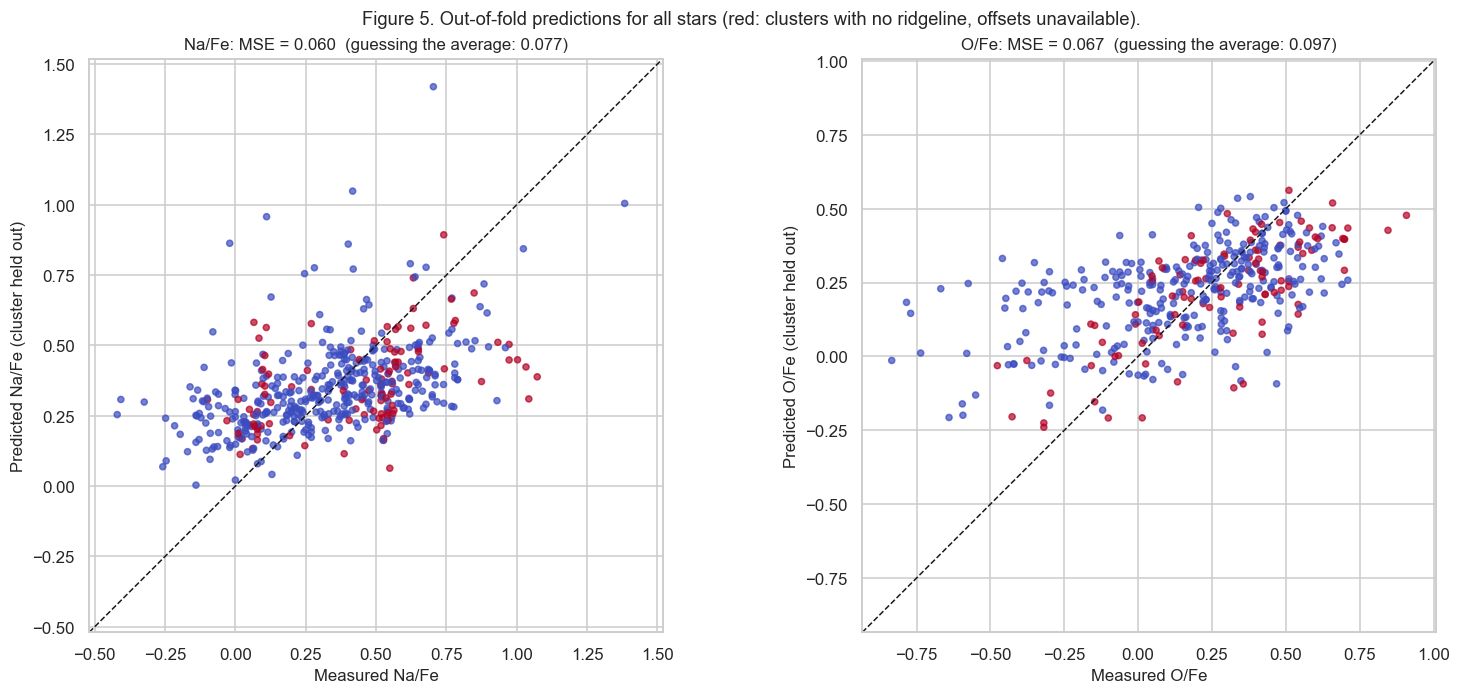

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2), constrained_layout=True)
oof_mse = {}
for ax, target in zip(axes, TARGETS):
    cols_t = FEATURE_SETS[main[target]['features']]
    d = df.dropna(subset=[target])
    X, y, g = d[cols_t].to_numpy(), d[target].to_numpy(), d['NGC'].to_numpy()
    P = grouped_cv_predict(MODELS[main[target]['model']], X, y, g, seed=7)
    oof_mse[target] = (mse(P, y), y.var())
    sc = ax.scatter(y, P, s=16, alpha=0.7, c=np.where(d['has_ridge'] == 1, 0, 1), cmap='coolwarm')
    lo, hi = min(y.min(), P.min()) - 0.1, max(y.max(), P.max()) + 0.1
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect('equal')
    ax.set_xlabel(f'Measured {target}'); ax.set_ylabel(f'Predicted {target} (cluster held out)')
    ax.set_title(f'{target}: MSE = {oof_mse[target][0]:.3f}  (guessing the average: {oof_mse[target][1]:.3f})')
fig.suptitle('Figure 5. Out-of-fold predictions for all stars (red: clusters with no ridgeline, offsets unavailable).', fontsize=12)
plt.show()

In [ ]:
g = rep.groupby('target')
display(Markdown(f"""
## Summary of findings

| | **Na/Fe** | **O/Fe** |
|---|---|---|
| Test MSE if guessing the average (this split) | {main['Na/Fe']['mse_baseline']:.3f} | {main['O/Fe']['mse_baseline']:.3f} |
| **Test MSE, held-out clusters, split of Figure 3** | **{main['Na/Fe']['mse_test']:.3f}** | **{main['O/Fe']['mse_test']:.3f}** |
| Train MSE | {main['Na/Fe']['mse_train']:.3f} | {main['O/Fe']['mse_train']:.3f} |
| Test R² on this split | {1 - main['Na/Fe']['mse_test'] / main['Na/Fe']['mse_baseline']:.2f} | {1 - main['O/Fe']['mse_test'] / main['O/Fe']['mse_baseline']:.2f} |
| Test MSE averaged over {N_REPEATS} random cluster splits | {g['test_mse'].mean()['Na/Fe']:.3f} \u00b1 {g['test_mse'].std()['Na/Fe']:.3f} (baseline {g['baseline'].mean()['Na/Fe']:.3f}) | {g['test_mse'].mean()['O/Fe']:.3f} \u00b1 {g['test_mse'].std()['O/Fe']:.3f} (baseline {g['baseline'].mean()['O/Fe']:.3f}) |
| Average share of variance explained on unseen clusters (R\u00b2) | {g['R2'].mean()['Na/Fe']:.2f} | {g['R2'].mean()['O/Fe']:.2f} |
| Splits where we beat the baseline | {int((rep[rep.target=='Na/Fe'].R2 > 0).sum())} of {N_REPEATS} | {int((rep[rep.target=='O/Fe'].R2 > 0).sum())} of {N_REPEATS} |
| All stars predicted out-of-fold (Figure 5) | {oof_mse['Na/Fe'][0]:.3f} vs {oof_mse['Na/Fe'][1]:.3f} baseline | {oof_mse['O/Fe'][0]:.3f} vs {oof_mse['O/Fe'][1]:.3f} baseline |

**Take-away.** Photometry carries real but partial information about a star's Na/Fe and O/Fe. On clusters the model has never seen, it beats the guess-the-average baseline in {int((rep[rep.target=='Na/Fe'].R2 > 0).sum())} of {N_REPEATS} (Na/Fe) and {int((rep[rep.target=='O/Fe'].R2 > 0).sum())} of {N_REPEATS} (O/Fe) random splits, but on average it explains only about {g['R2'].mean()['Na/Fe']*100:.0f}% (Na/Fe) and {g['R2'].mean()['O/Fe']*100:.0f}% (O/Fe) of the variance, with a large spread from split to split. The old protocol (random split of stars) made the problem look much easier than it is (Figure 2). Correcting for dust helps consistently; the ridgeline offsets help some models more than others. The single split of Figure 3 is not typical (see its R² against the averages), so the repeated-split row is the fair summary.
"""))


## Summary of findings

| | **Na/Fe** | **O/Fe** |
|---|---|---|
| Test MSE if guessing the average (this split) | 0.105 | 0.057 |
| **Test MSE, held-out clusters, split of Figure 3** | **0.087** | **0.026** |
| Train MSE | 0.048 | 0.041 |
| Test R² on this split | 0.17 | 0.53 |
| Test MSE averaged over 10 random cluster splits | 0.053 ± 0.011 (baseline 0.074) | 0.076 ± 0.028 (baseline 0.090) |
| Average share of variance explained on unseen clusters (R²) | 0.27 | 0.15 |
| Splits where we beat the baseline | 9 of 10 | 8 of 10 |
| All stars predicted out-of-fold (Figure 5) | 0.060 vs 0.077 baseline | 0.067 vs 0.097 baseline |

**Take-away.** Photometry carries real but partial information about a star's Na/Fe and O/Fe. On clusters the model has never seen, it beats the guess-the-average baseline in 9 of 10 (Na/Fe) and 8 of 10 (O/Fe) random splits, but on average it explains only about 27% (Na/Fe) and 15% (O/Fe) of the variance, with a large spread from split to split. The old protocol (random split of stars) made the problem look much easier than it is (Figure 2). Correcting for dust helps consistently; the ridgeline offsets help some models more than others. The single split of Figure 3 is not typical (see its R² against the averages), so the repeated-split row is the fair summary.


## 7. Caveats and next steps

* **Small number of clusters.** About 27 clusters, a few with only a handful of stars. Held-out scores vary a lot from split to split (Figure 4). We therefore rely on the repeated-split average rather than one number.
* **Abundance measurement noise.** Na/Fe and O/Fe come from several papers and methods with their own offsets and errors. We did not model per-paper differences, which probably sets a floor on the achievable error.
* **Dust correction.** Uses a catalogue E(B−V) per cluster, a fixed R_V = 3.1 law, and one red-giant temperature. A small dust residual remains in the ultraviolet colours (see the dereddening report).
* **Ridgeline offsets** are only available for clusters in the HUGS ridgeline set; stars from the others (including ω Centauri, the largest cluster here) get offset 0 and a flag, so the model cannot use that information for them.
* **Selection effects.** The input set and model were chosen on the training clusters only (40 combinations), and the held-out clusters were scored once; the repeated splits redo the whole selection each time. Differences of ~0.002 in MSE are ties, and with 40 candidates the winner of the inner cross-validation is partly luck, which is one reason the test error is higher than the training cross-validation error suggests.
* **Few clusters, large split-to-split spread.** The test error changes a lot with which clusters are held out (Figure 4). More clusters with abundances would help more than any modelling change.
* **An earlier variant.** A run in which the input set was fixed in advance to the last one (with only the model selected) gave similar repeated-split averages (about 0.051 for Na/Fe and 0.072 for O/Fe over 15 splits). That choice had been informed by exploratory analysis on all clusters, so we report the fully nested version here. The two are within each other's noise.
* The old neural-network and KAN pipelines were not rerun; the tree/SVR models here were competitive on this small dataset, and a neural net with so few clusters is unlikely to help.

**Possible next steps:** (1) per-paper offset correction for the abundance labels; (2) include the F438W-axis ridgelines to get offsets for more stars; (3) fit E(B−V) per cluster rather than using the catalogue value; (4) predict Na/Fe and O/Fe jointly, since they are anti-correlated within a cluster; (5) use cluster-level summaries (fraction of second-generation stars) as an intermediate target.